In [25]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.datasets import make_regression
from sklearn.linear_model import Lasso 



[26.54455684]
-4.6953782418895


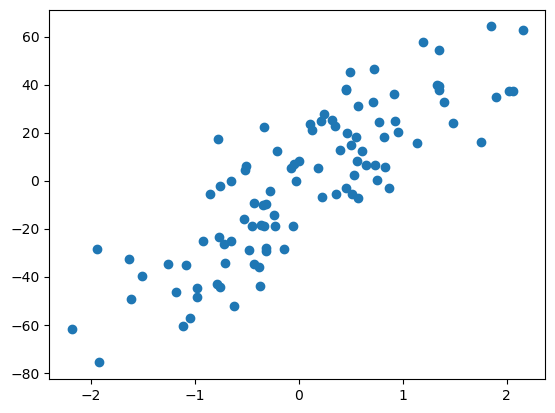

In [26]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

plt.scatter(X,y)

from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train,y_train)
print(reg.coef_)
print(reg.intercept_)

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.563e+03, tolerance: 6.524e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinat

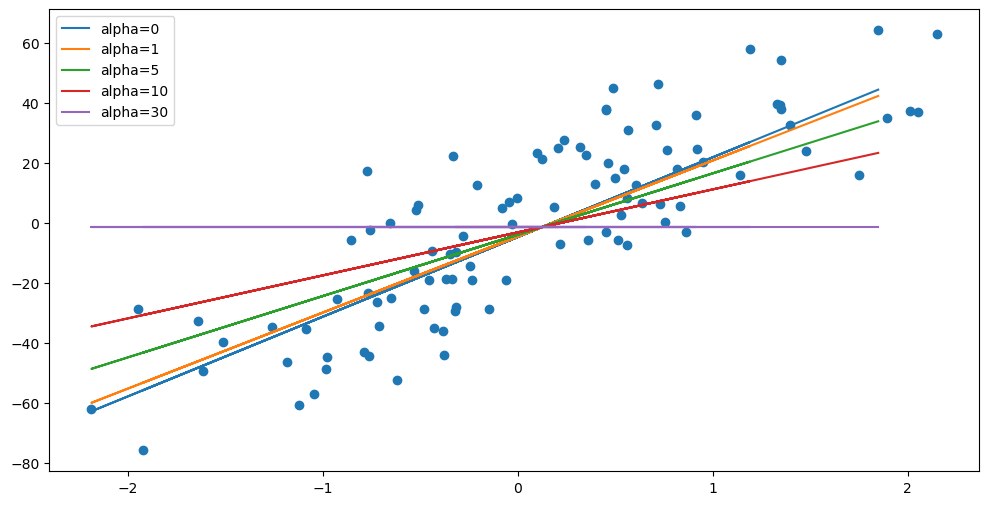

In [27]:
alphas = [0,1,5,10,30]
plt.figure(figsize=(12,6))
plt.scatter(X,y)
for i in alphas:
    L = Lasso(alpha=i)
    L.fit(X_train,y_train)
    plt.plot(X_test,L.predict(X_test),label='alpha={}'.format(i))
plt.legend()
plt.show()

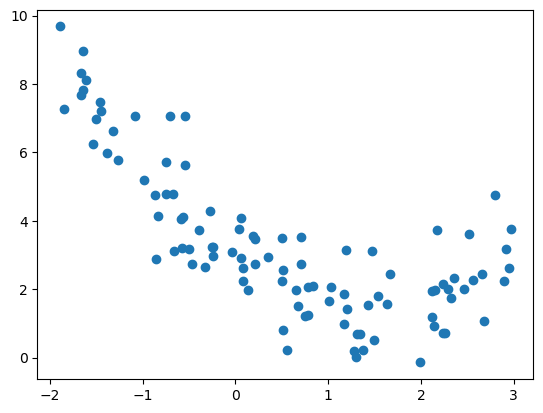

In [28]:
m = 100
x1 = 5 * np.random.rand(m, 1) - 2
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 + np.random.randn(m, 1)

plt.scatter(x1, x2)
plt.show()

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.473e+01, tolerance: 4.964e-02 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinat

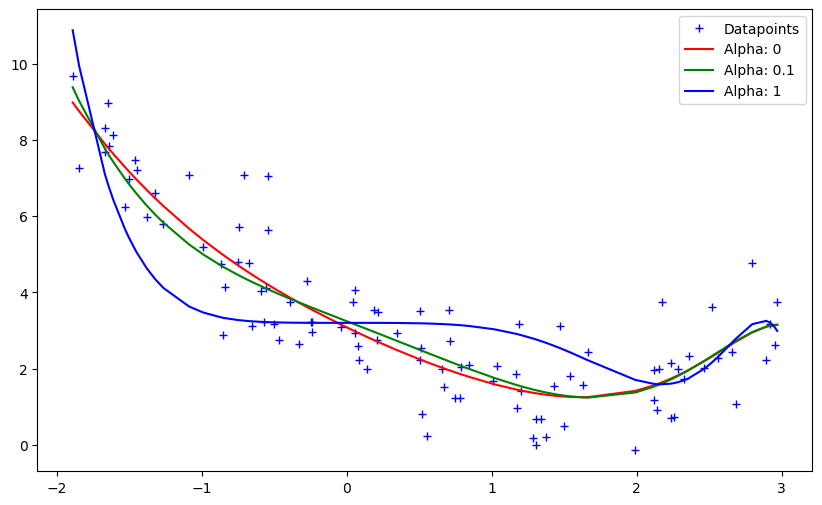

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

def get_preds_lasso(x1, x2, alpha):
    model = Pipeline([
        ('poly_feats', PolynomialFeatures(degree=16)),
        ('lasso', Lasso(alpha=alpha))
    ])
    model.fit(x1, x2)
    return model.predict(x1)

alphas = [0, 0.1, 1]
cs = ['r', 'g', 'b']

plt.figure(figsize=(10, 6))
plt.plot(x1, x2, 'b+', label='Datapoints')

for alpha, c in zip(alphas, cs):
    preds = get_preds_lasso(x1, x2, alpha)
    # Plot
    plt.plot(sorted(x1[:, 0]), preds[np.argsort(x1[:, 0])], c, label='Alpha: {}'.format(alpha))

plt.legend()
plt.show()

In [10]:
from sklearn.metrics import r2_score , mean_squared_error 

print("r2_score", r2_score(y_test , y_pred))
print("MSE", mean_squared_error(y_test , y_pred))
print("RMSE", np.sqrt(mean_squared_error(y_test , y_pred)))

r2_score 0.5188113124539249
MSE 2374.3339396183187
RMSE 48.72713760953252


In [11]:
from sklearn.linear_model import Ridge 
R = Ridge(alpha = 0.0001)

In [12]:
R.fit(X_train , y_train)


Ridge(alpha=0.0001)

In [13]:
y_pred1 = R.predict(X_test)

In [14]:
from sklearn.metrics import r2_score , mean_squared_error 

print("r2_score", r2_score(y_test , y_pred1))
print("MSE", mean_squared_error(y_test , y_pred1))
print("RMSE", np.sqrt(mean_squared_error(y_test , y_pred1)))

r2_score 0.518973263588495
MSE 2373.5348225872626
RMSE 48.718937001819555


## overfitting & underfitting kaise hota h 


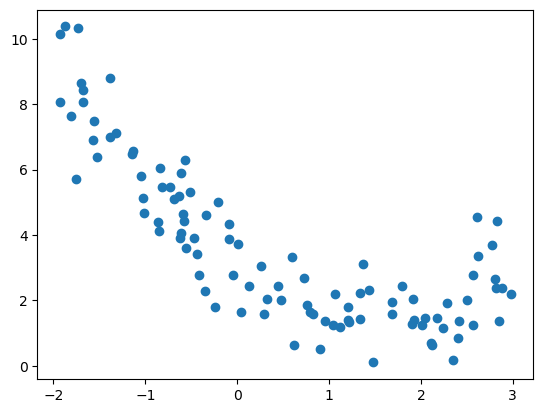

In [15]:

m = 100
x1 = 5 * np.random.rand(m , 1) - 2 
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 +  np.random.randn(m , 1)

plt.scatter(x1 , x2)
plt.show()

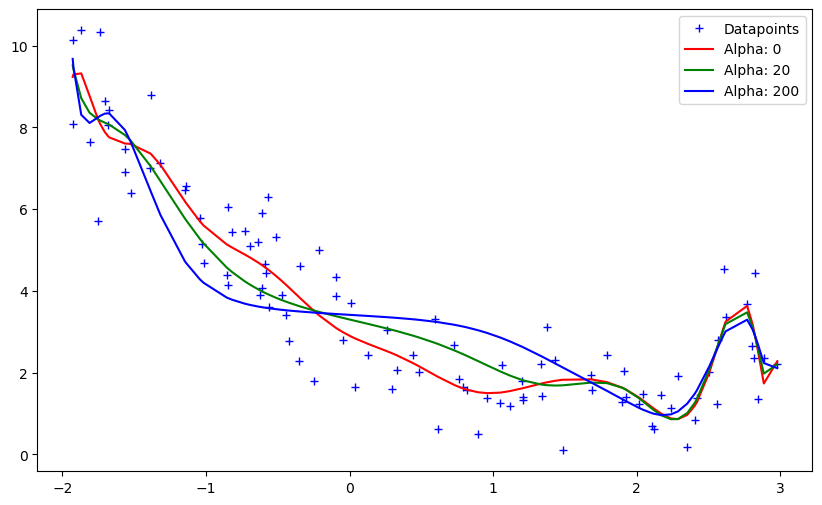

In [21]:
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import PolynomialFeatures

def get_pred_ridge(x1 , x2 , alpha):
    model = Pipeline([
        ('poly_feats' , PolynomialFeatures(degree = 16)),
        ('ridge' , Ridge(alpha=alpha))
        
    ])
    model.fit(x1 , x2)
    return model.predict(x1)

alpha = [0 , 20 , 200]

cs = ['r' , 'g' , 'b']

plt.figure(figsize = (10 , 6))
plt.plot(x1 , x2 , 'b+' , label = 'Datapoints')

for alpha , c in zip(alpha , cs):
    preds = get_pred_ridge(x1 , x2 , alpha)
    # plot 
    plt.plot(sorted(x1[:,0]) , preds[np.argsort(x1[:,0])] , c , label = 'Alpha: {}'.format(alpha))

plt.legend()
plt.show()